In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r'../../data/bbc-text-1.csv')

df.head()

,category,text
0,tech,tv future in the hands of viewers with home th...
1,business,worldcom boss left books alone former worldc...
2,sport,tigers wary of farrell gamble leicester say ...
3,sport,yeading face newcastle in fa cup premiership s...
4,entertainment,ocean s twelve raids box office ocean s twelve...


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   category  2225 non-null   str  
 1   text      2225 non-null   str  
dtypes: str(2)
memory usage: 34.9 KB


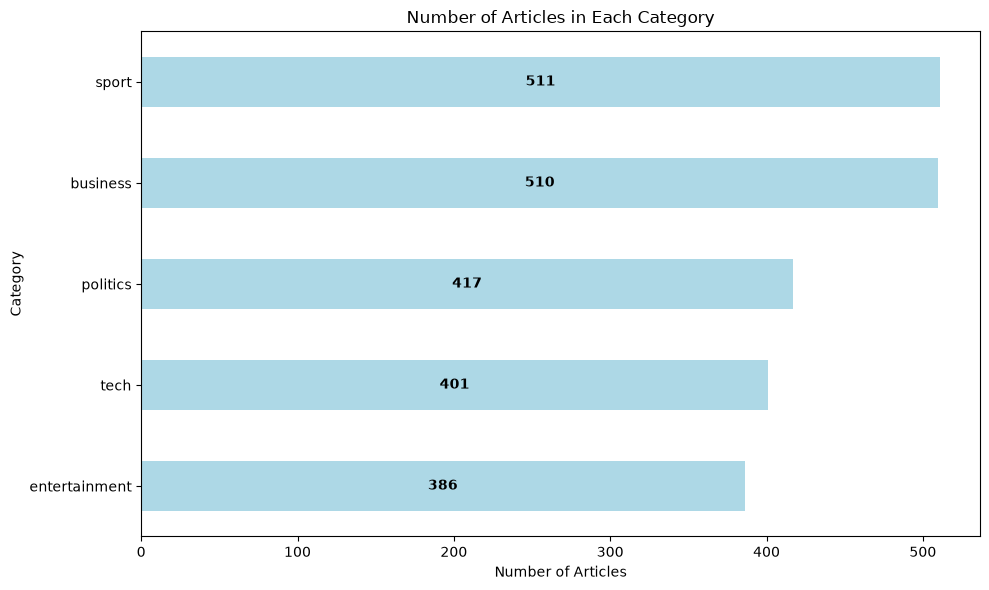

In [4]:
fig, axes = plt.subplots(figsize=(10, 6))

bars = df['category'].value_counts().sort_values(ascending=False).plot(
    kind='barh',
    color='lightblue',
    ax=axes
)

axes.set_title('Number of Articles in Each Category')
axes.set_xlabel('Number of Articles')
axes.set_ylabel('Category')

for bar in axes.patches:
    width = bar.get_width()
    y = bar.get_y() + bar.get_height() / 2

    axes.text(
        width / 2,
        y,
        f'{int(width)}',
        ha='center',
        va='center',
        color='black',
        fontweight='bold'
    )

axes.invert_yaxis()

plt.tight_layout()
plt.show()

In [5]:
# Ordinal Encoding of the 'category' column
from sklearn.preprocessing import OrdinalEncoder

ordinal_encoder = OrdinalEncoder()

df['category_encoded'] = ordinal_encoder.fit_transform(df[['category']])
df.head()

,category,text,category_encoded
0,tech,tv future in the hands of viewers with home th...,4.0
1,business,worldcom boss left books alone former worldc...,0.0
2,sport,tigers wary of farrell gamble leicester say ...,3.0
3,sport,yeading face newcastle in fa cup premiership s...,3.0
4,entertainment,ocean s twelve raids box office ocean s twelve...,1.0


In [6]:
X = df['text']
y = df['category']

In [10]:
def P_class(y, class_label):
    return np.sum(y == class_label) / len(y)

In [11]:
P_class(y, 'business')

np.float64(0.2292134831460674)

In [33]:
def P_word_given_class(X, y, word, class_label, vocab_size):

    X_class = X[y == class_label]

    # Count the number of documents in the class
    num_docs_in_class = len(X_class)

    # Count documents containing the word (literal matching)
    num_docs_with_word_in_class = np.sum(
        X_class.str.contains(word, case=False, regex=False, na=False)
    )

    # Laplace smoothing
    return (num_docs_with_word_in_class + 1) / (
        num_docs_in_class + vocab_size
    )

In [19]:
from collections import Counter
word_counts = Counter()
X.str.split().apply(word_counts.update)
word_counts.most_common(10)

[('the', 52567),
 ('to', 24955),
 ('of', 19947),
 ('and', 18561),
 ('a', 18251),
 ('in', 17570),
 ('s', 9007),
 ('for', 8884),
 ('is', 8515),
 ('that', 8135)]

In [20]:
P_word_given_class(X, y, 'market', 'business', vocab_size=len(word_counts))

np.float64(0.00584900973329419)

In [22]:
# Multinomial Naive Bayes Classifier Implementation
test_text = "The stock market is experiencing a significant downturn due to global economic uncertainties."
tokenized_test_text = test_text.split()
# remove tokens that are not in the vocabulary
vocab = set(word_counts.keys())
filtered_tokens = [token for token in tokenized_test_text if token in vocab]

# Score for sport class
score_market = P_class(y, 'sport')
for token in filtered_tokens:
    score_market *= P_word_given_class(X, y, token, 'sport', vocab_size=len(word_counts))

# Score for business class
score_business = P_class(y, 'business')
for token in filtered_tokens:
    score_business *= P_word_given_class(X, y, token, 'business', vocab_size=len(word_counts))

# Score for politics class
score_politics = P_class(y, 'politics')
for token in filtered_tokens:
    score_politics *= P_word_given_class(X, y, token, 'politics', vocab_size=len(word_counts))

# Score for tech class
score_tech = P_class(y, 'tech')
for token in filtered_tokens:
    score_tech *= P_word_given_class(X, y, token, 'tech', vocab_size=len(word_counts))

# Score for entertainment class
score_entertainment = P_class(y, 'entertainment')
for token in filtered_tokens:
    score_entertainment *= P_word_given_class(X, y, token, 'entertainment', vocab_size=len(word_counts))


In [26]:
predicted_class = max(
    {
        'sport': score_market,
        'business': score_business,
        'politics': score_politics,
        'tech': score_tech,
        'entertainment': score_entertainment
    },
    key=lambda k: {
        'sport': score_market,
        'business': score_business,
        'politics': score_politics,
        'tech': score_tech,
        'entertainment': score_entertainment
    }[k]
)
print(f"The predicted class for the test text is: {predicted_class}")

The predicted class for the test text is: business


In [34]:
class MultinomialNaiveBayes:

    def __init__(self):
        self.class_priors = {}
        self.word_likelihoods = {}
        self.vocab = set()
        self.vocab_size = 0

    def fit(self, X, y):

        self.vocab = set(
            word.lower()
            for text in X
            for word in text.split()
        )

        self.vocab_size = len(self.vocab)

        classes = np.unique(y)

        for class_label in classes:

            self.class_priors[class_label] = P_class(
                y, class_label
            )

            self.word_likelihoods[class_label] = {}

            for word in self.vocab:

                self.word_likelihoods[class_label][word] = (
                    P_word_given_class(
                        X, y, word,
                        class_label,
                        self.vocab_size
                    )
                )

    def predict(self, X):

        predictions = []

        for text in X:

            tokens = [
                word.lower()
                for word in text.split()
                if word.lower() in self.vocab
            ]

            scores = {}

            for class_label in self.class_priors:

                score = np.log(
                    self.class_priors[class_label]
                )

                for token in tokens:

                    score += np.log(
                        self.word_likelihoods[class_label][token]
                    )

                scores[class_label] = score

            predictions.append(
                max(scores, key=scores.get)
            )

        return predictions


In [35]:
model_multinomial = MultinomialNaiveBayes()
model_multinomial.fit(X, y)

In [40]:
model_multinomial.predict(["Roller coasters are a popular attraction in amusement parks, providing thrilling experiences for visitors. People play games, enjoy rides, and indulge in various entertainment options, making it a favorite destination for families and thrill-seekers alike."])

['tech']

In [43]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

In [44]:
len(X_train), len(X_test), len(y_train), len(y_test)

(2002, 223, 2002, 223)

In [45]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [46]:
model = MultinomialNaiveBayes()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9013452914798207
Classification Report:
               precision    recall  f1-score   support

     business       0.92      0.96      0.94        46
entertainment       1.00      0.64      0.78        44
     politics       0.94      0.94      0.94        47
        sport       0.94      1.00      0.97        48
         tech       0.76      0.97      0.85        38

     accuracy                           0.90       223
    macro avg       0.91      0.90      0.89       223
 weighted avg       0.91      0.90      0.90       223

Confusion Matrix:
[[44  0  2  0  0]
 [ 1 28  1  2 12]
 [ 3  0 44  0  0]
 [ 0  0  0 48  0]
 [ 0  0  0  1 37]]
